# Start

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import matplotlib.dates as mdates


In [2]:
bcalc_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results\Dataframes\Bcalc_8okt2026.xlsx"
chemcalc_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results\Dataframes\chemcalc_8okt2026.xlsx"    #carbon_30sep2026(7)

bcalc_df = pd.read_excel(bcalc_path)
chemcalc_df = pd.read_excel(chemcalc_path)

conc_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_modeling\Data\AVP2016_concentrations_data.xlsx"
lake_data_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Data\Verspagen_AmstelveensePoel.xlsx"
AVP_DIC_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Data\AVP-DIC-pH.xlsx"

conc_data = pd.read_excel(conc_path)
lake_data2 = pd.read_excel(lake_data_path, sheet_name="HF_WQ")
AVP_DIC = pd.read_excel(AVP_DIC_path, header=1)

In [3]:
conc_data = conc_data[:][0:-3] # Remove NaN rows
conc_data = conc_data[(conc_data["date"]> "2016-05-17")]
lake_data2["date"] = pd.to_datetime(
    lake_data2["date_time_ymd_hms"]
)

AVP_DIC = AVP_DIC[AVP_DIC["DIC (Alk, pH)"] < 0.01].copy()

In [4]:
### OUTPUT ###

output_dir = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results"

# plots

## combined plots and difference plots

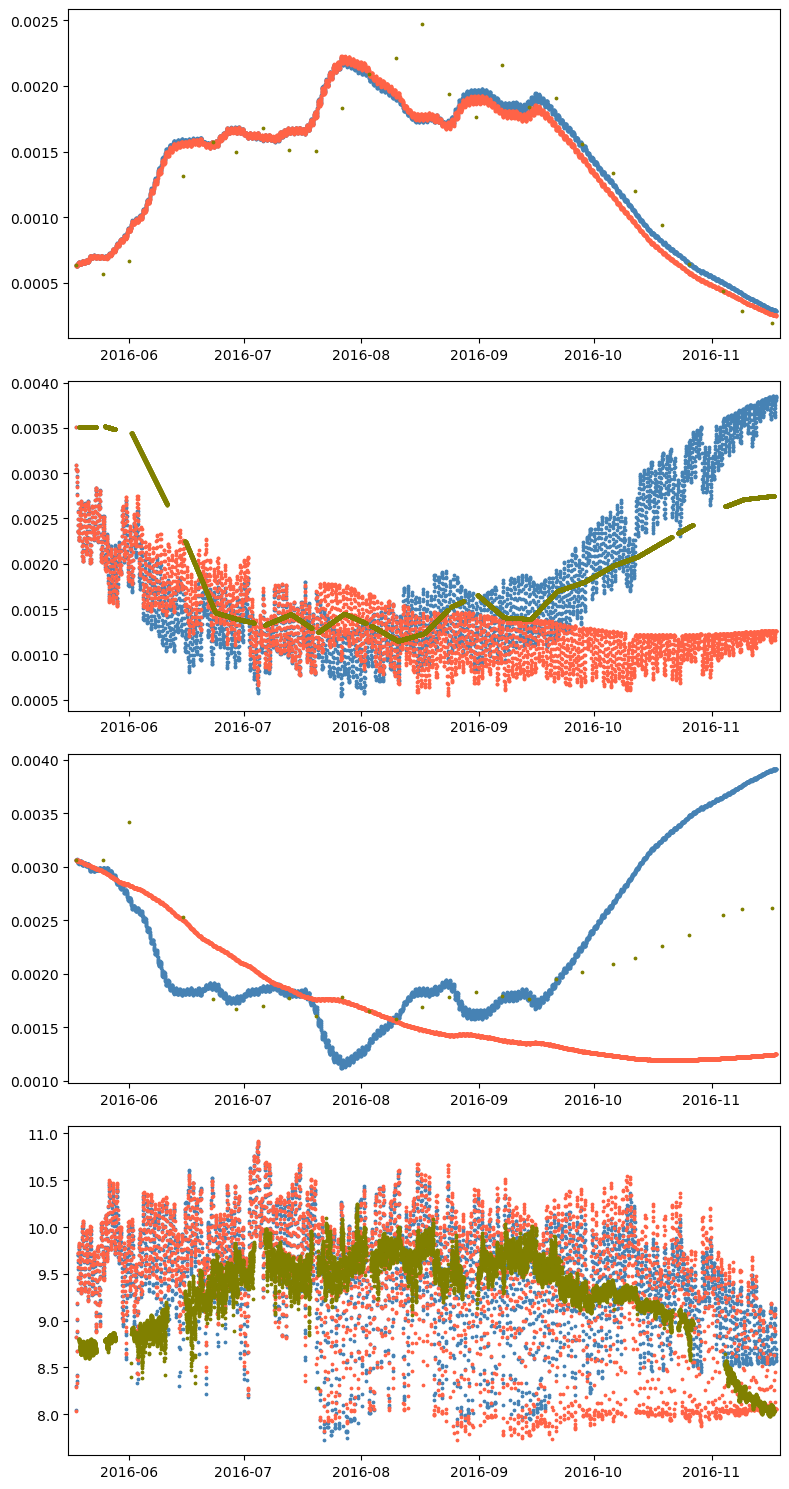

In [177]:
fig, axs = plt.subplots(4, figsize=(8, 15))

axs[0].scatter(bcalc_df["date"], bcalc_df["B"], s=3, color="steelblue")
axs[0].scatter(chemcalc_df["date"], chemcalc_df["B"], s=3, color="tomato")
axs[0].scatter(conc_data["date"], conc_data["POC"]/ (10**6), s=3, color="olive")

axs[1].scatter(bcalc_df["date"], bcalc_df['DIC'], s=3, color="steelblue")
axs[1].scatter(chemcalc_df['date'], chemcalc_df['DIC'], s=3, color="tomato")
axs[1].scatter(lake_data2['date'], lake_data2['DIC_umolL']*(10**-6), s=3, color="olive")

axs[2].scatter(bcalc_df["date"], bcalc_df['Alk'], s=3, color="steelblue")
axs[2].scatter(chemcalc_df['date'], chemcalc_df['Alk'], s=3, color="tomato")
axs[2].scatter(conc_data['date'], conc_data['Alk']*(10**-6), s=3, color="olive")

axs[3].scatter(bcalc_df["date"], bcalc_df['pH'], s=3, color="steelblue")
axs[3].scatter(chemcalc_df['date'], chemcalc_df['pH'], s=3, color="tomato")
axs[3].scatter(lake_data2['date'], lake_data2['sensor_pH'], s=3, color="olive")


for ax in axs:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))

plt.tight_layout()

## Main plots

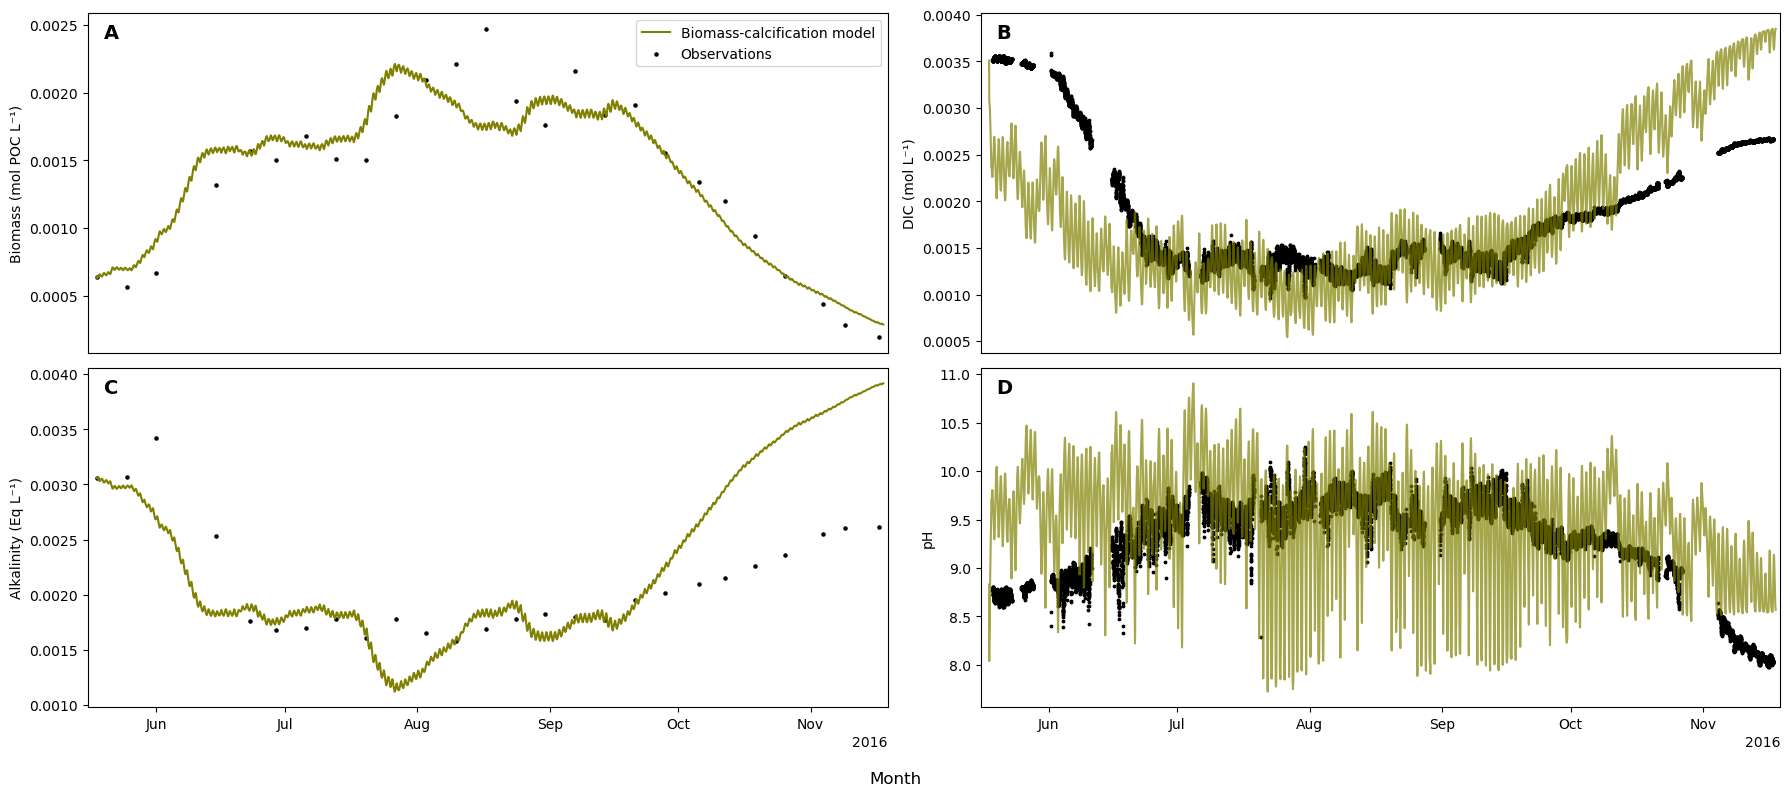

In [17]:
fig, axs = plt.subplots(2,2, figsize=(18, 8))

axs[0,0].plot(bcalc_df["date"], bcalc_df["B"], color="olive")
axs[0,0].scatter(conc_data["date"], conc_data["POC"]/ (10**6), s=5, color="black")
axs[0,0].set_ylabel('Biomass (mol POC L⁻¹)')

axs[0,1].plot(bcalc_df["date"], bcalc_df['DIC'], color="olive", alpha=0.7)
# axs[0,1].scatter(lake_data2['date'], lake_data2['DIC_umolL']*(10**-6), s=3, color="black")
axs[0,1].scatter(AVP_DIC['Time'], AVP_DIC["DIC (Alk, pH)"], s=3, color="black")
axs[0,1].set_ylabel('DIC (mol L⁻¹)')

axs[1,0].plot(bcalc_df["date"], bcalc_df['Alk'], color="olive")
axs[1,0].scatter(conc_data['date'], conc_data['Alk']*(10**-6), s=5, color="black")
axs[1,0].set_ylabel('Alkalinity (Eq L⁻¹)')

axs[1,1].plot(bcalc_df["date"], bcalc_df['pH'], color="olive", alpha=0.7)
axs[1,1].scatter(lake_data2['date'], lake_data2['sensor_pH'], s=3, color="black")
axs[1,1].set_ylabel('pH')

for ax in axs.flat:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))

locator = mdates.AutoDateLocator()
axs[1,0].xaxis.set_major_locator(locator)
axs[1,0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

axs[1,1].xaxis.set_major_locator(locator)
axs[1,1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

for ax in axs[0, :]:
    ax.tick_params(axis="x", bottom=False, labelbottom=False)

# fig.suptitle("Biomass-calcification model compared with observations", fontsize=16)
axs[0,0].legend(["Biomass-calcification model", "Observations"], loc='upper right')
fig.supxlabel("Month")

for ax, label in zip(axs.flat, "ABCD"):
    ax.text(
        0.02, 0.97, label,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=14, fontweight="bold"
    )

plt.tight_layout()

##### Saving #####
out = os.path.join(output_dir, f"Plots\\Bcalc_model.png")
plt.savefig(out)

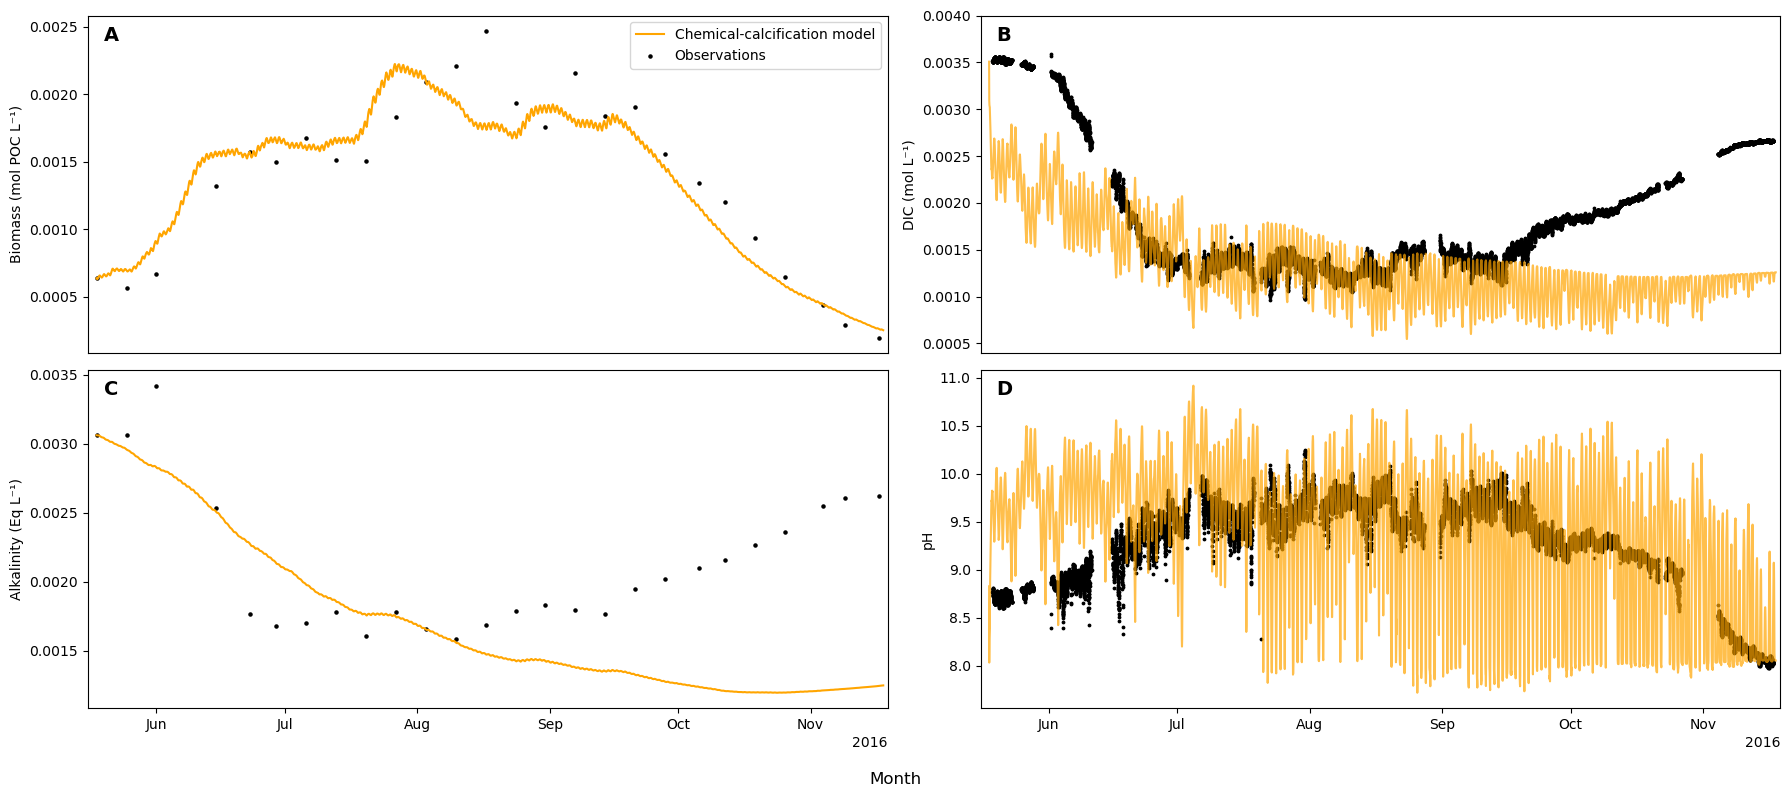

In [33]:
fig, axs = plt.subplots(2,2, figsize=(18, 8))

axs[0,0].plot(chemcalc_df["date"], chemcalc_df["B"], color="orange")
axs[0,0].scatter(conc_data["date"], conc_data["POC"]/ (10**6), s=5, color="black")
axs[0,0].set_ylabel('Biomass (mol POC L⁻¹)')

axs[0,1].plot(chemcalc_df["date"], chemcalc_df['DIC'], color="orange", alpha=0.7)
# axs[0,1].scatter(lake_data2['date'], lake_data2['DIC_umolL']*(10**-6), s=3, color="black")
axs[0,1].scatter(AVP_DIC['Time'], AVP_DIC["DIC (Alk, pH)"], s=3, color="black")
axs[0,1].set_ylabel('DIC (mol L⁻¹)')
axs[0,1].set_ylim(top=0.0040)

axs[1,0].plot(chemcalc_df["date"], chemcalc_df['Alk'], color="orange")
axs[1,0].scatter(conc_data['date'], conc_data['Alk']*(10**-6), s=5, color="black")
axs[1,0].set_ylabel('Alkalinity (Eq L⁻¹)')

axs[1,1].plot(chemcalc_df["date"], chemcalc_df['pH'], color="orange", alpha=0.7)
axs[1,1].scatter(lake_data2['date'], lake_data2['sensor_pH'], s=3, color="black")
axs[1,1].set_ylabel('pH')

for ax in axs.flat:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))

locator = mdates.AutoDateLocator()
axs[1,0].xaxis.set_major_locator(locator)
axs[1,0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

axs[1,1].xaxis.set_major_locator(locator)
axs[1,1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

for ax in axs[0, :]:
    ax.tick_params(axis="x", bottom=False, labelbottom=False)

# fig.suptitle("Chemical-calcification model compared with observations", fontsize=16)
axs[0,0].legend(["Chemical-calcification model", "Observations"], loc='upper right')
fig.supxlabel("Month")

for ax, label in zip(axs.flat, "ABCD"):
    ax.text(
        0.02, 0.97, label,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=14, fontweight="bold"
    )

plt.tight_layout()

##### Saving #####
out = os.path.join(output_dir, f"Plots\\Chemcalc_model.png")
plt.savefig(out)

In [219]:
chemcalc_df['K_sp']

0                NaN
1       3.732420e-09
2       3.732420e-09
3       3.732420e-09
4       3.732420e-09
            ...     
4412    3.957094e-09
4413    3.957094e-09
4414    3.957094e-09
4415    3.957094e-09
4416    3.957094e-09
Name: K_sp, Length: 4417, dtype: float64

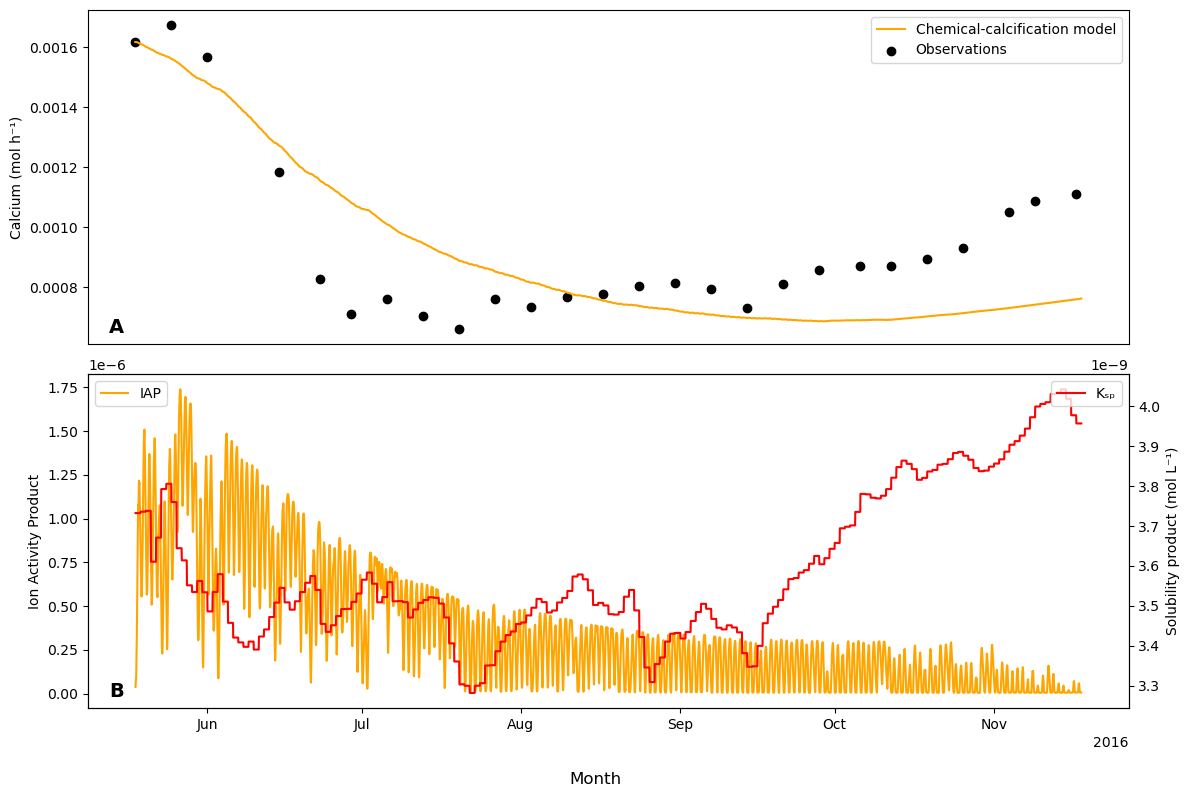

In [31]:
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12,8))

axs[0].plot(chemcalc_df["date"], chemcalc_df['Ca'], color="orange")
axs[0].scatter(conc_data['date'], conc_data['Ca']/ (10**6), color='black')
axs[0].set_ylabel("Calcium (mol h⁻¹)")
axs[0].tick_params(axis="x", bottom=False, labelbottom=False)

axs[1].plot(chemcalc_df["date"], chemcalc_df['IAP'], color="orange")
# axs[1].plot(chemcalc_df["date"], chemcalc_df['K_sp'], color="orange")
axs[1].set_ylabel("Ion Activity Product")
ax_right = axs[1].twinx()
ax_right.plot(chemcalc_df["date"], chemcalc_df["K_sp"], color="red")
ax_right.set_ylabel("Solubility product (mol L⁻¹)")

# for ax in axes:
#     ax.grid(alpha=0.3)

locator = mdates.AutoDateLocator()
axs[1].xaxis.set_major_locator(locator)
axs[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

# axs[0].set_title("Environmental inputs")
fig.supxlabel("Month")
axs[0].legend(["Chemical-calcification model", "Observations"], loc='upper right')
axs[1].legend(["IAP", "Kₛₚ"], loc='upper left')
ax_right.legend(["Kₛₚ"], loc='upper right')

for ax, label in zip(axs.flat, "AB"):
    ax.text(
        0.02, 0.02, label,
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=14, fontweight="bold")

# fig.suptitle("Calcification Components", fontsize=16)

plt.tight_layout()

### Saving ###
out = os.path.join(output_dir, f"Plots\\Calcification_plots.png")
plt.savefig(out)
##############

plt.show()

## Nutrient plots

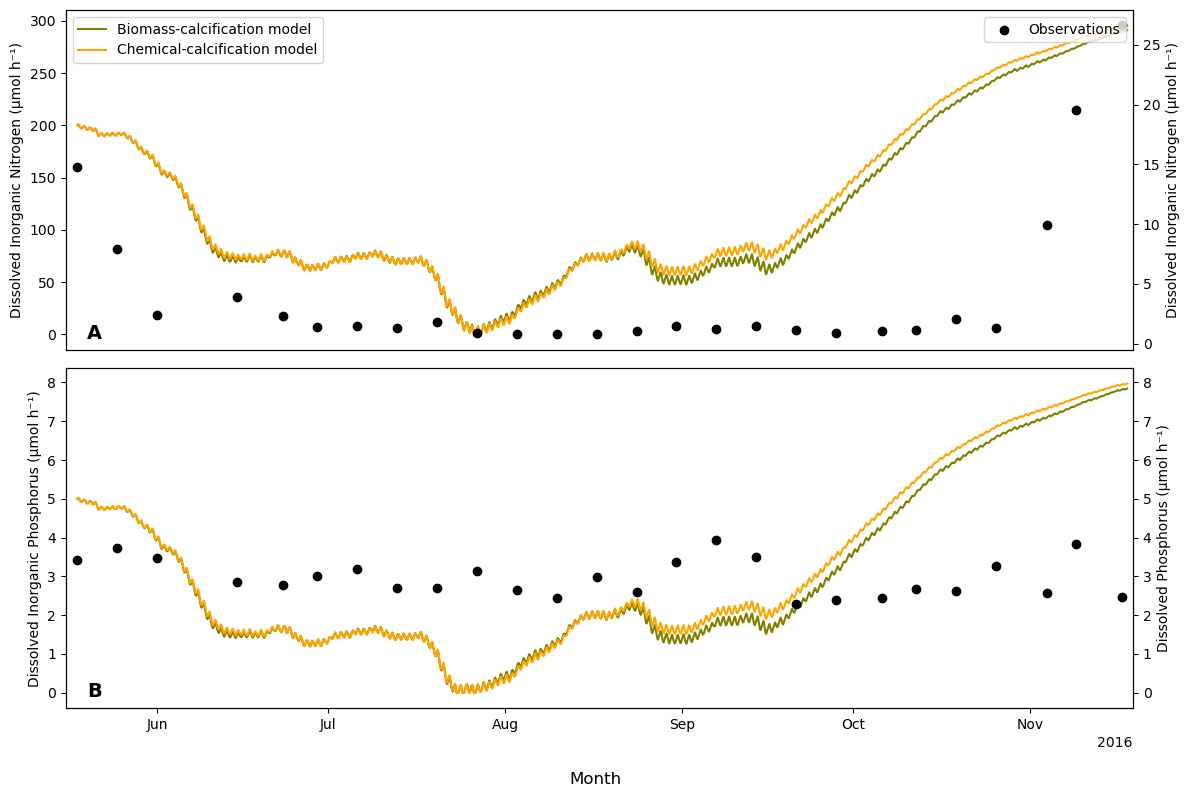

In [39]:
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12,8))

axs[0].plot(bcalc_df["date"], bcalc_df['N']*10**6, color="olive")
axs[0].plot(chemcalc_df["date"], chemcalc_df['N']*10**6, color="orange")
axs[0].set_ylabel("Dissolved Inorganic Nitrogen (µmol h⁻¹)")
axs[0].tick_params(axis="x", bottom=False, labelbottom=False)

ax_right = axs[0].twinx()
ax_right.scatter(conc_data['date'], conc_data['DIN'], color='black')
ax_right.set_ylabel("Dissolved Inorganic Nitrogen (µmol h⁻¹)")
ax_right.tick_params(axis="x", bottom=False, labelbottom=False)


axs[1].plot(bcalc_df["date"], bcalc_df['P_t']*10**6, color="olive")
axs[1].plot(chemcalc_df["date"], chemcalc_df['P_t']*10**6, color="orange")
# axs[1].scatter(conc_data['date'], conc_data['P'], color='black')
axs[1].set_ylabel("Dissolved Inorganic Phosphorus (µmol h⁻¹)")

ax_right2 = axs[1].twinx()
ax_right2.scatter(conc_data['date'], conc_data['P'], color='black')
ax_right2.set_ylim(axs[1].get_ylim())
ax_right2.set_ylabel("Dissolved Phosphorus (µmol h⁻¹)")

for ax in axs.flat:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))

# for ax in axes:
#     ax.grid(alpha=0.3)

locator = mdates.AutoDateLocator()
axs[1].xaxis.set_major_locator(locator)
axs[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

# axs[0].set_title("Environmental inputs")
fig.supxlabel("Month")
axs[0].legend(["Biomass-calcification model", "Chemical-calcification model"], loc='upper left')
ax_right.legend(["Observations"], loc='upper right')

# fig.suptitle("Nutrient Concentrations", fontsize=16)

for ax, label in zip(axs.flat, "AB"):
    ax.text(
        0.02, 0.02, label,
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=14, fontweight="bold"
    )
    
plt.tight_layout()

### Saving ###
out = os.path.join(output_dir, f"Plots\\Nutrient_concentrations.png")
plt.savefig(out)
##############

plt.show()

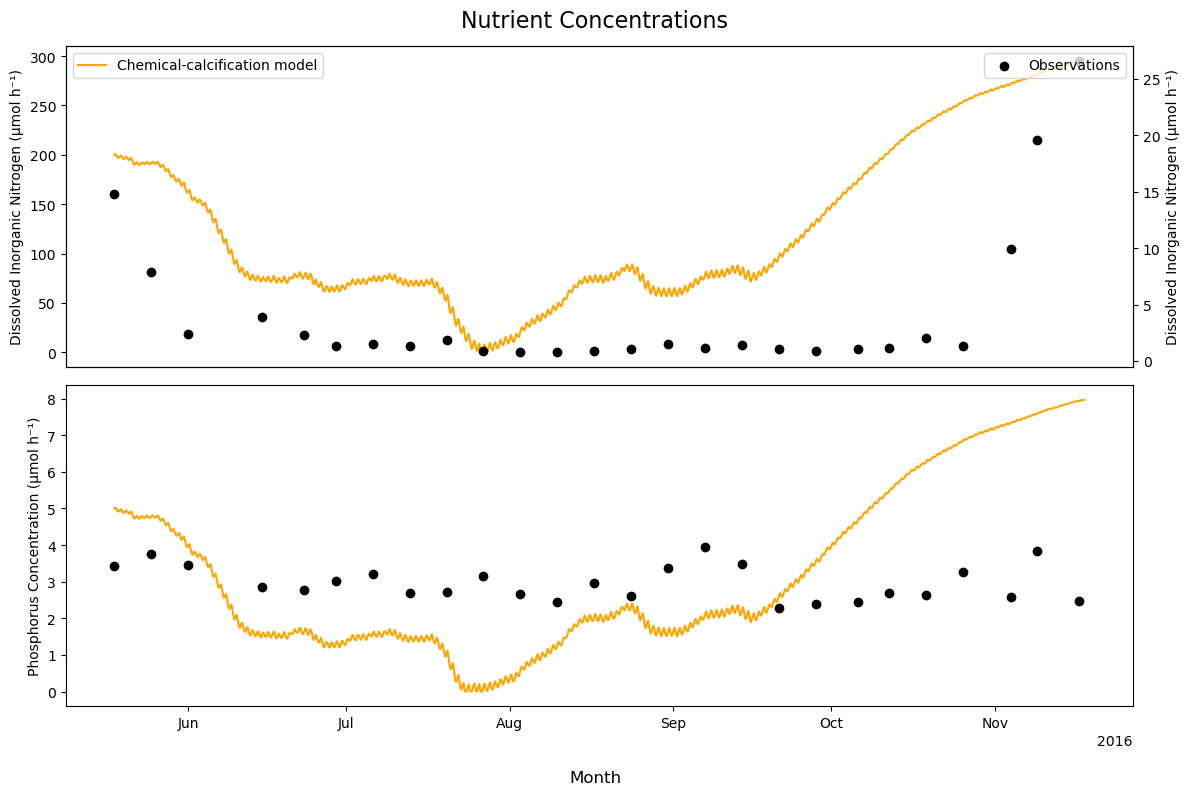

In [301]:
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12,8))

axs[0].plot(chemcalc_df["date"], chemcalc_df['N']*10**6, color="orange")
axs[0].set_ylabel("Dissolved Inorganic Nitrogen (µmol h⁻¹)")
axs[0].tick_params(axis="x", bottom=False, labelbottom=False)

ax_right = axs[0].twinx()
ax_right.scatter(conc_data['date'], conc_data['DIN'], color='black')
ax_right.set_ylabel("Dissolved Inorganic Nitrogen (µmol h⁻¹)")
ax_right.tick_params(axis="x", bottom=False, labelbottom=False)


axs[1].plot(chemcalc_df["date"], chemcalc_df['P_t']*10**6, color="orange")
axs[1].scatter(conc_data['date'], conc_data['P'], color='black')
axs[1].set_ylabel("Phosphorus Concentration (µmol h⁻¹)")

# for ax in axes:
#     ax.grid(alpha=0.3)

locator = mdates.AutoDateLocator()
axs[1].xaxis.set_major_locator(locator)
axs[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

# axs[0].set_title("Environmental inputs")
fig.supxlabel("Month")
axs[0].legend(["Chemical-calcification model"], loc='upper left')
ax_right.legend(["Observations"], loc='upper right')

fig.suptitle("Nutrient Concentrations", fontsize=16)

### Saving ###
# out = os.path.join(output_dir, f"Plots\\Calcification_plots.png")
# plt.savefig(out)
##############

plt.tight_layout()
plt.show()

# Statistics

## Biomass

In [131]:
bcalc_df["date"].iloc[0]

Timestamp('2016-05-18 00:00:00')

In [76]:
########### increase ##############
obs_increase = conc_data[(conc_data["date"]< "2016-06-24")]
bcalc_increase = bcalc_df[(bcalc_df["date"]< "2016-06-24")]
chemcalc_increase = chemcalc_df[(chemcalc_df["date"]< "2016-06-24")]

print('observed increase: ', (obs_increase['POC'].iloc[-1] - obs_increase['POC'].iloc[0]) *(10**-6))
print('Bcalc increase: ', bcalc_increase['B'].iloc[-1] - bcalc_increase['B'].iloc[0])
print('Chemcalc increase: ', chemcalc_increase['B'].iloc[-1] - chemcalc_increase['B'].iloc[0])

observed increase:  0.0009351208333333327
Bcalc increase:  0.000930496398448605
Chemcalc increase:  0.000928480344320709


In [78]:
################## summer peak ####################3
print("max observed:", np.max(conc_data['POC'])/(10**6), "         date:", conc_data.loc[conc_data["POC"].idxmax(), "date"])
print("max Bcalc:", np.max(bcalc_df['B']), "         date:", bcalc_df.loc[bcalc_df["B"].idxmax(), "date"])
print("max Chemcalc:", np.max(chemcalc_df['B']), "         date:", chemcalc_df.loc[chemcalc_df["B"].idxmax(), "date"])

max observed: 0.002470971111111111          date: 2016-08-17 00:00:00
max Bcalc: 0.002211213890185274          date: 2016-07-26 18:00:00
max Chemcalc: 0.002224639562857629          date: 2016-07-26 18:00:00


In [80]:
############## high period #################
obs_high = conc_data[(conc_data["date"]>= "2016-06-23") & (conc_data["date"] < "2016-09-22")]
bcalc_high = bcalc_df[(bcalc_df["date"]>= "2016-06-23") & (bcalc_df["date"] < "2016-09-22")]
chemcalc_high = chemcalc_df[(chemcalc_df["date"]>= "2016-06-23") & (chemcalc_df["date"] < "2016-09-22")]

print('observed high period average: ', np.average(obs_high['POC'])*(10**-6))
print('Bcalc high period average: ', np.average(bcalc_high['B']))
print('Chemcalc high period average: ', np.average(chemcalc_high['B']))

observed high period average:  0.0018548399056752332
Bcalc high period average:  0.0018283387230273785
Chemcalc high period average:  0.0018151384610644217


In [82]:
########### decline #############
obs_decrease = conc_data[(conc_data["date"]>= "2016-09-21") & (conc_data["date"]<= "2016-11-17")]
bcalc_decrease = bcalc_df[(bcalc_df["date"]>= "2016-09-21") & (bcalc_df["date"]<= "2016-11-17")]
chemcalc_decrease = chemcalc_df[(chemcalc_df["date"]>= "2016-09-21") & (chemcalc_df["date"]<= "2016-11-17")]

print('observed decrease: ', (obs_decrease['POC'].iloc[-1] - obs_decrease['POC'].iloc[0]) *(10**-6))
print('Bcalc decrease: ', bcalc_decrease['B'].iloc[-1] - bcalc_decrease['B'].iloc[0])
print('Chemcalc decrease: ', chemcalc_decrease['B'].iloc[-1] - chemcalc_decrease['B'].iloc[0])

observed decrease:  -0.001711312638888889
Bcalc decrease:  -0.0014797573712820034
Chemcalc decrease:  -0.0014282491852951047


In [84]:
############ end concentration #################
print("last observed:", obs_decrease["POC"].iloc[-1]/(10**6), "       date:", conc_data["date"].iloc[-1])
print("last Bcalc:", bcalc_decrease["B"].iloc[-1], "       date:", bcalc_decrease["date"].iloc[-1])
print("last Chemcalc:", chemcalc_decrease["B"].iloc[-1], "       date:", chemcalc_decrease["date"].iloc[-1])

last observed: 0.00019314847222222224        date: 2016-11-17 00:00:00
last Bcalc: 0.0002966813751632068        date: 2016-11-17 00:00:00
last Chemcalc: 0.0002595987304722463        date: 2016-11-17 00:00:00


## DIC

In [87]:
######## Decline ##############
obs_DIC_decline = lake_data2[(lake_data2["date"]< "2016-06-30") & (lake_data2["date"]>= "2016-06-01")]
bcalc_DIC_decline = bcalc_df[(bcalc_df["date"]< "2016-06-30") & (bcalc_df["date"]>= "2016-06-01")]
chemcalc_DIC_decline = chemcalc_df[(chemcalc_df["date"]< "2016-06-30") & (chemcalc_df["date"]>= "2016-06-01")]

print('observed decline: ', (obs_DIC_decline['DIC_umolL'].iloc[-1] - obs_DIC_decline['DIC_umolL'].iloc[0]) *(10**-6))
print('Bcalc decline: ', bcalc_DIC_decline['DIC'].iloc[-1] - bcalc_DIC_decline['DIC'].iloc[0])
print('Chemcalc decline: ', chemcalc_DIC_decline['DIC'].iloc[-1] - chemcalc_DIC_decline['DIC'].iloc[0])

observed decline:  -0.002066124666333
Bcalc decline:  -0.000681739212314892
Chemcalc decline:  -0.0005130056815760161


In [89]:
############## low period #################
obs_DIC_low = lake_data2[(lake_data2["date"]>= "2016-06-29") & (lake_data2["date"] < "2016-09-15")]
bcalc_DIC_low = bcalc_df[(bcalc_df["date"]>= "2016-06-29") & (bcalc_df["date"] < "2016-09-15")]
chemcalc_DIC_low = chemcalc_df[(chemcalc_df["date"]>= "2016-06-29") & (chemcalc_df["date"] < "2016-09-15")]

print('observed low period average: ', np.average(obs_DIC_low['DIC_umolL'])*(10**-6))
print('Bcalc low period average: ', np.average(bcalc_DIC_low['DIC']))
print('Chemcalc low period average: ', np.average(chemcalc_DIC_low['DIC']))

observed low period average:  0.001366701488363483
Bcalc low period average:  0.001253974665841965
Chemcalc low period average:  0.0012155332887382785


In [91]:
############### Increase ###############
obs_DIC_increase = lake_data2[(lake_data2["date"]>= "2016-09-14") & (lake_data2["date"]<= "2016-11-17")]
bcalc_DIC_increase = bcalc_df[(bcalc_df["date"]>= "2016-09-14") & (bcalc_df["date"]<= "2016-11-17")]
chemcalc_DIC_increase = chemcalc_df[(chemcalc_df["date"]>= "2016-09-14") & (chemcalc_df["date"]<= "2016-11-17")]

print('observed increase: ', (obs_DIC_increase['DIC_umolL'].iloc[-1] - obs_DIC_increase['DIC_umolL'].iloc[0]) *(10**-6))
print('Bcalc increase: ', bcalc_DIC_increase['DIC'].iloc[-1] - bcalc_DIC_increase['DIC'].iloc[0])
print('Chemcalc increase: ', chemcalc_DIC_increase['DIC'].iloc[-1] - chemcalc_DIC_increase['DIC'].iloc[0])

observed increase:  0.001358094582888242
Bcalc increase:  0.0021118767294170592
Chemcalc increase:  -9.769264395506996e-05


In [125]:
############ end concentration #################
print("last observed:", obs_DIC_increase["DIC_umolL"].iloc[-1]/(10**6), "       date:", lake_data2["date"].iloc[-1])
print("last Bcalc:", bcalc_DIC_increase["DIC"].iloc[-14], "       date:", bcalc_df["date"].iloc[-14])
print("last Chemcalc:", chemcalc_DIC_increase["DIC"].iloc[-14], "       date:", chemcalc_df["date"].iloc[-14])

last observed: 0.0027491637533652224        date: 2016-11-17 11:00:19.980000
last Bcalc: 0.003702812766195456        date: 2016-11-17 11:00:00
last Chemcalc: 0.001177797902529705        date: 2016-11-17 11:00:00


## Alkalinity

In [96]:
######## Decline ##############
obs_Alk_decline = conc_data[(conc_data["date"]< "2016-06-30") & (conc_data["date"]>= "2016-06-01")]
bcalc_Alk_decline = bcalc_df[(bcalc_df["date"]< "2016-06-30") & (bcalc_df["date"]>= "2016-06-01")]
chemcalc_Alk_decline = chemcalc_df[(chemcalc_df["date"]< "2016-06-30") & (chemcalc_df["date"]>= "2016-06-01")]

print('observed decline: ', (obs_Alk_decline['Alk'].iloc[-1] - obs_Alk_decline['Alk'].iloc[0]) *(10**-6))
print('Bcalc decline: ', bcalc_Alk_decline['Alk'].iloc[-1] - bcalc_Alk_decline['Alk'].iloc[0])
print('Chemcalc decline: ', chemcalc_Alk_decline['Alk'].iloc[-1] - chemcalc_Alk_decline['Alk'].iloc[0])

observed decline:  -0.0017427312
Bcalc decline:  -0.000936473795197497
Chemcalc decline:  -0.0007141790101787208


In [98]:
############## low period #################
obs_Alk_low = conc_data[(conc_data["date"]>= "2016-06-29") & (conc_data["date"] < "2016-09-15")]
bcalc_Alk_low = bcalc_df[(bcalc_df["date"]>= "2016-06-29") & (bcalc_df["date"] < "2016-09-15")]
chemcalc_Alk_low = chemcalc_df[(chemcalc_df["date"]>= "2016-06-29") & (chemcalc_df["date"] < "2016-09-15")]

print('observed low period average: ', np.average(obs_Alk_low['Alk'])*(10**-6))
print('Bcalc low period average: ', np.average(bcalc_Alk_low['Alk']))
print('Chemcalc low period average: ', np.average(chemcalc_Alk_low['Alk']))

observed low period average:  0.0017200714403846152
Bcalc low period average:  0.0016648949315747198
Chemcalc low period average:  0.001634184795466806


In [100]:
############### Increase ###############
obs_Alk_increase = conc_data[(conc_data["date"]>= "2016-09-14") & (conc_data["date"]<= "2016-11-17")]
bcalc_Alk_increase = bcalc_df[(bcalc_df["date"]>= "2016-09-14") & (bcalc_df["date"]<= "2016-11-17")]
chemcalc_Alk_increase = chemcalc_df[(chemcalc_df["date"]>= "2016-09-14") & (chemcalc_df["date"]<= "2016-11-17")]

print('observed increase: ', (obs_Alk_increase['Alk'].iloc[-1] - obs_Alk_increase['Alk'].iloc[0]) *(10**-6))
print('Bcalc increase: ', bcalc_Alk_increase['Alk'].iloc[-1] - bcalc_Alk_increase['Alk'].iloc[0])
print('Chemcalc increase: ', chemcalc_Alk_increase['Alk'].iloc[-1] - chemcalc_Alk_increase['Alk'].iloc[0])

observed increase:  0.0008495493333333338
Bcalc increase:  0.002108292505024918
Chemcalc increase:  -0.0001061706983926259


In [137]:
############ end concentration #################
print("last observed:", obs_Alk_increase["Alk"].iloc[-1]/(10**6), "       date:", conc_data["date"].iloc[-1])
print("last Bcalc:", bcalc_Alk_increase["Alk"].iloc[-1], "       date:", bcalc_Alk_increase["date"].iloc[-1])
print("last Chemcalc:", chemcalc_Alk_increase["Alk"].iloc[-1], "       date:", chemcalc_Alk_increase["date"].iloc[-1])

last observed: 0.0026177733333333335        date: 2016-11-17 00:00:00
last Bcalc: 0.003904817796627067        date: 2016-11-17 00:00:00
last Chemcalc: 0.001244570338616748        date: 2016-11-17 00:00:00


## pH

In [105]:
########### increase ##############
obs_pH_increase = lake_data2[(lake_data2["date"]<= "2016-07-06")]
bcalc_pH_increase = bcalc_df[(bcalc_df["date"]<= "2016-07-06")]
chemcalc_pH_increase = chemcalc_df[(chemcalc_df["date"]<= "2016-07-06")]

print('observed increase: ', (obs_pH_increase['sensor_pH'].iloc[-1] - obs_pH_increase['sensor_pH'].iloc[0]))
print('Bcalc increase: ', bcalc_pH_increase['pH'].iloc[-1] - bcalc_pH_increase['pH'].iloc[0])
print('Chemcalc increase: ', chemcalc_pH_increase['pH'].iloc[-1] - chemcalc_pH_increase['pH'].iloc[0])

observed increase:  1.0093554545454548
Bcalc increase:  0.848321833868777
Chemcalc increase:  0.8659978327975661


In [107]:
############## high period #################
obs_pH_high = lake_data2[(lake_data2["date"]>= "2016-07-06") & (lake_data2["date"] < "2016-09-15")]
bcalc_pH_high = bcalc_df[(bcalc_df["date"]>= "2016-07-06") & (bcalc_df["date"] < "2016-09-15")]
chemcalc_pH_high = chemcalc_df[(chemcalc_df["date"]>= "2016-07-06") & (chemcalc_df["date"] < "2016-09-15")]

print('observed high period average: ', np.average(obs_pH_high['sensor_pH']))
print('Bcalc high period average: ', np.average(bcalc_pH_high['pH']))
print('Chemcalc high period average: ', np.average(chemcalc_pH_high['pH']))

observed high period average:  9.632022229943862
Bcalc high period average:  9.495884060785402
Chemcalc high period average:  9.50204330955051


In [109]:
########### decline #############
obs_pH_decrease = lake_data2[(lake_data2["date"]>= "2016-09-14") & (lake_data2["date"]<= "2016-11-17")]
bcalc_pH_decrease = bcalc_df[(bcalc_df["date"]>= "2016-09-14") & (bcalc_df["date"]<= "2016-11-17")]
chemcalc_pH_decrease = chemcalc_df[(chemcalc_df["date"]>= "2016-09-14") & (chemcalc_df["date"]<= "2016-11-17")]

print('observed decrease: ', (obs_pH_decrease['sensor_pH'].iloc[-1] - obs_pH_decrease['sensor_pH'].iloc[0]))
print('Bcalc decrease: ', bcalc_pH_decrease['pH'].iloc[-1] - bcalc_pH_decrease['pH'].iloc[0])
print('Chemcalc decrease: ', chemcalc_pH_decrease['pH'].iloc[-1] - chemcalc_pH_decrease['pH'].iloc[0])

observed decrease:  -1.773755454545455
Bcalc decrease:  -0.07320907037109947
Chemcalc decrease:  -0.0038265180774992302


In [111]:
############## end period #################
obs_pH_end = lake_data2[(lake_data2["date"]>= "2016-11-09") & (lake_data2["date"]<= "2016-11-17")]
bcalc_pH_end = bcalc_df[(bcalc_df["date"]>= "2016-11-09") & (bcalc_df["date"]<= "2016-11-17")]
chemcalc_pH_end = chemcalc_df[(chemcalc_df["date"]>= "2016-11-09") & (chemcalc_df["date"]<= "2016-11-17")]

print('observed high period average: ', np.average(obs_pH_end['sensor_pH']))
print('Bcalc high period average: ', np.average(bcalc_pH_end['pH']))
print('Chemcalc high period average: ', np.average(chemcalc_pH_end['pH']))

observed high period average:  8.125707004294918
Bcalc high period average:  8.841740099735222
Chemcalc high period average:  8.41598446729533


## Calcium

In [203]:
########### decline #############
obs_Ca_decline = conc_data[(conc_data["date"]< "2016-06-30") & (conc_data["date"]>= "2016-06-01")]
chemcalc_Ca_decline = chemcalc_df[(chemcalc_df["date"]< "2016-06-30") & (chemcalc_df["date"]>= "2016-06-01")]

print('observed decline: ', (obs_Ca_decline['Ca'].iloc[-1] - obs_Ca_decline['Ca'].iloc[0]) *(10**-6))
print('Chemcalc decline: ', chemcalc_Ca_decline['Ca'].iloc[-1] - chemcalc_Ca_decline['Ca'].iloc[0])

observed decline:  -0.0008586295900430824
Chemcalc decline:  -0.00041050927496347504


In [207]:
############## low period #################
obs_Ca_low = conc_data[(conc_data["date"]>= "2016-06-29") & (conc_data["date"] < "2016-09-15")]
chemcalc_Ca_low = chemcalc_df[(chemcalc_df["date"]>= "2016-06-29") & (chemcalc_df["date"] < "2016-09-15")]

print('observed low period average: ', np.average(obs_Ca_low['Ca'])*(10**-6))
print('Chemcalc low period average: ', np.average(chemcalc_Ca_low['Ca']))

observed low period average:  0.0007514337575653384
Chemcalc low period average:  0.0008260800094446285


In [211]:
############### Increase ###############
obs_Ca_increase = conc_data[(conc_data["date"]>= "2016-09-14") & (conc_data["date"]<= "2016-11-17")]
chemcalc_Ca_increase = chemcalc_df[(chemcalc_df["date"]>= "2016-09-14") & (chemcalc_df["date"]<= "2016-11-17")]

print('observed increase: ', (obs_Ca_increase['Ca'].iloc[-1] - obs_Ca_increase['Ca'].iloc[0]) *(10**-6))
print('Chemcalc increase: ', chemcalc_Ca_increase['Ca'].iloc[-1] - chemcalc_Ca_increase['Ca'].iloc[0])

observed increase:  0.00037997777420594435
Chemcalc increase:  6.236779965756263e-05


In [213]:
############ end concentration #################
print("last observed:", obs_Ca_increase["Ca"].iloc[-1]/(10**6), "       date:", obs_Ca_increase["date"].iloc[-1])
print("last Chemcalc:", chemcalc_Ca_increase["Ca"].iloc[-1], "       date:", chemcalc_Alk_increase["date"].iloc[-1])

last observed: 0.0011113393128116904        date: 2016-11-17 00:00:00
last Chemcalc: 0.0007594292064215793        date: 2016-11-17 00:00:00


## IAP

In [ ]:
IAPCO3_increase = chemcalc_df[(chemcalc_df["date"]< "2016-05-28")]
IAPCO3_decrease = chemcalc_df[(chemcalc_df["date"]>= "2016-05-27") & (chemcalc_df["date"]< "2016-07-28")]
IAPCO3_slowdecrease = chemcalc_df[(chemcalc_df["date"]>= "2016-07-27") & (chemcalc_df["date"]< "2016-11-02")]
IAPCO3_finaldecrease = chemcalc_df[(chemcalc_df["date"]>= "2016-11-01") & (chemcalc_df["date"]<= "2016-11-17")]



print('IAP increase: ', IAPCO3_increase['IAP'].iloc[-1] - IAPCO3_increase['IAP'].iloc[0])
print('IAP peak: ', np.max(IAPCO3_increase['IAP']))
print('IAP decrease: ', IAPCO3_decrease['IAP'].iloc[-1] - IAPCO3_decrease['IAP'].iloc[0])
print('IAP slow decrease: ', IAPCO3_slowdecrease['IAP'].iloc[-1] - IAPCO3_slowdecrease['IAP'].iloc[0])
print('IAP final decrease: ', IAPCO3_finaldecrease['IAP'].iloc[-1] - IAPCO3_finaldecrease['IAP'].iloc[0])

print(" ")
print('CO3 increase: ', IAPCO3_increase['CO3'].iloc[-1] - IAPCO3_increase['CO3'].iloc[0])
print('CO3 peak: ', np.max(IAPCO3_increase['IAP']))
print('CO3 decrease: ', IAPCO3_decrease['CO3'].iloc[-1] - IAPCO3_decrease['CO3'].iloc[0])
print('CO3 slow decrease: ', IAPCO3_slowdecrease['CO3'].iloc[-1] - IAPCO3_slowdecrease['CO3'].iloc[0])
print('CO3 final decrease: ', IAPCO3_finaldecrease['CO3'].iloc[-1] - IAPCO3_finaldecrease['CO3'].iloc[0])


In [27]:
#Get avarages
IAPCO3_daily = chemcalc_df[["date", "IAP", "CO3"]].copy()
IAPCO3_daily = IAPCO3_daily.dropna(subset=["date"]).set_index("date").resample("D")[["IAP", "CO3"]].mean().reset_index()

IAPCO3_increase = IAPCO3_daily[(IAPCO3_daily["date"]< "2016-05-28")]
IAPCO3_decrease = IAPCO3_daily[(IAPCO3_daily["date"]>= "2016-05-27") & (IAPCO3_daily["date"]< "2016-07-28")]
IAPCO3_decrease2 = IAPCO3_daily[(IAPCO3_daily["date"]>= "2016-07-27") & (IAPCO3_daily["date"]<= "2016-11-17")]

print('IAP increase: ', IAPCO3_increase['IAP'].iloc[-1] - IAPCO3_increase['IAP'].iloc[0])
print('IAP peak: ', np.max(chemcalc_df['IAP']), "         date:", chemcalc_df.loc[chemcalc_df["IAP"].idxmax(), "date"])
print('IAP decrease: ', IAPCO3_decrease['IAP'].iloc[-1] - IAPCO3_decrease['IAP'].iloc[0])
print('IAP 2nd decrease: ', IAPCO3_decrease2['IAP'].iloc[-1] - IAPCO3_decrease2['IAP'].iloc[0])
print('IAP end average: ', IAPCO3_decrease2['IAP'].iloc[-1], "       date:", IAPCO3_decrease2["date"].iloc[-1])


print(" ")
print('CO3 increase: ', IAPCO3_increase['CO3'].iloc[-1] - IAPCO3_increase['CO3'].iloc[0])
print('CO3 peak: ', np.max(chemcalc_df['CO3']), "         date:", chemcalc_df.loc[chemcalc_df["CO3"].idxmax(), "date"])
print('CO3 decrease: ', IAPCO3_decrease['CO3'].iloc[-1] - IAPCO3_decrease['CO3'].iloc[0])
print('CO3 2nd decrease: ', IAPCO3_decrease2['CO3'].iloc[-1] - IAPCO3_decrease2['CO3'].iloc[0])
print('CO3 end average: ', IAPCO3_decrease2['CO3'].iloc[-1], "       date:", IAPCO3_decrease2["date"].iloc[-1])


IAP increase:  6.90691266578583e-07
IAP peak:  1.738045005548072e-06          date: 2016-05-26 18:00:00
IAP decrease:  -1.1820721914372936e-06
IAP 2nd decrease:  -2.2735918346051447e-07
IAP end average:  1.7344082793336057e-08        date: 2016-11-17 00:00:00
 
CO3 increase:  0.0004876503021084724
CO3 peak:  0.001126830660126047          date: 2016-05-26 18:00:00
CO3 decrease:  -0.0006433768857543414
CO3 2nd decrease:  -0.00026539872609375204
CO3 end average:  2.2802505403738784e-05        date: 2016-11-17 00:00:00


In [13]:
IAPCO3_daily

,IAP,CO3
date,,
2016-05-18,7.360842e-07,0.000444
2016-05-19,1.029977e-06,0.000641
2016-05-20,9.684482e-07,0.000606
2016-05-21,1.010831e-06,0.000636
2016-05-22,8.396333e-07,0.000531
...,...,...
2016-11-14,1.374591e-08,0.000018
2016-11-15,9.156322e-09,0.000012
2016-11-16,1.997400e-08,0.000026
